# Week 9 live coding: clustering

A 45-minute tutorial to type through together. It covers the three clustering methods from
this week's lecture, k-means, DBSCAN, and Gaussian mixture models, and the questions that
matter more than the algorithms: how many clusters, how stable are they, and what do they
mean.

We work with **national carbon emissions and wealth** from Our World in Data, one row per
country for 2022. There are no labels. The question is whether countries fall into natural
groups by how much they emit, how rich they are, and where their energy comes from. For DBSCAN
we switch to data where distance has a physical meaning: the locations of **methane
super-emitters** across the United States, from Carbon Mapper. Assignment 8 applies the same
methods to gridded climate normals to find climate zones, so everything here transfers and
nothing here is the answer to the assignment.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("pandas ", pd.__version__)
print("sklearn", sklearn.__version__)

pandas  2.3.3
sklearn 1.7.2


## 1. Load the data and choose features

The Our World in Data CO$_2$ dataset is one CSV covering every country and year. We keep the
2022 rows for actual countries (the file also has aggregates such as "Asia" and "World",
which have no ISO code or an `OWID_` code) and build four features:

| Feature | Meaning |
| --- | --- |
| `co2_pc` | territorial CO$_2$ emissions per person, tonnes per year |
| `gdp_pc` | GDP per person, international dollars |
| `energy_pc` | primary energy use per person, kWh per year |
| `coal_share` | fraction of the country's CO$_2$ that comes from coal |

In [2]:
url = "https://github.com/owid/co2-data/raw/master/owid-co2-data.csv"
raw = pd.read_csv(url)
raw["iso_code"] = raw["iso_code"].fillna("")

c = raw[(raw["year"] == 2022) & (raw["iso_code"] != "") & ~raw["iso_code"].str.startswith("OWID")].copy()
c["gdp_pc"] = c["gdp"] / c["population"]
c["coal_share"] = c["coal_co2"] / c["co2"]
c = c.rename(columns={"co2_per_capita": "co2_pc", "energy_per_capita": "energy_pc"})

cols = ["co2_pc", "gdp_pc", "energy_pc", "coal_share"]
c = c.dropna(subset=cols).set_index("country")
print(len(c), "countries with all four features")
c[cols].describe().round(2)

129 countries with all four features


,co2_pc,gdp_pc,energy_pc,coal_share
count,129.00,129.00,129.00,129.00
mean,5.00,22418.99,28614.97,0.22
std,5.44,21062.71,33892.35,0.23
min,0.06,688.91,307.10,0.00
25%,1.40,7349.57,6909.17,0.03
50%,3.53,15810.63,18080.92,0.13
75%,6.78,32802.73,33835.21,0.38
max,37.89,131990.53,195336.34,0.91


Two things to notice in that summary. The per-capita columns span two to three orders of
magnitude, so we take logarithms: a doubling of income should count the same whether it
happens at 2,000 or 20,000 dollars. And the columns have wildly different units. Every
clustering method here works on **distances**, and a distance in raw units would be dominated
by whichever column has the biggest numbers. So we standardize.

In [3]:
from sklearn.preprocessing import StandardScaler

feat = pd.DataFrame({
    "log_co2_pc":    np.log10(c["co2_pc"]),
    "log_gdp_pc":    np.log10(c["gdp_pc"]),
    "log_energy_pc": np.log10(c["energy_pc"]),
    "coal_share":    c["coal_share"],
}, index=c.index)

scaler = StandardScaler().fit(feat)
X = scaler.transform(feat)
print("feature matrix:", X.shape)

feature matrix: (129, 4)


Look at the data before clustering it. Emissions against income is the natural view.

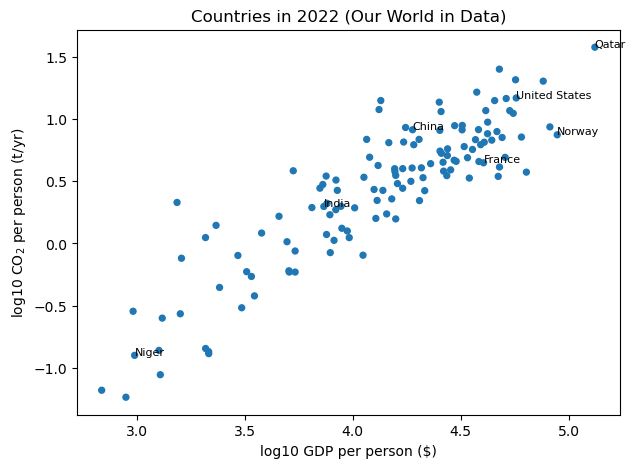

In [4]:
def scatter(ax, labels, title):
    x, y = feat["log_gdp_pc"], feat["log_co2_pc"]
    ax.scatter(x, y, c=labels, s=18, vmin=0, vmax=9,
               cmap=plt.cm.tab10.with_extremes(under="gray"))
    for name in ["Qatar", "United States", "China", "India", "Norway", "France", "Niger"]:
        ax.annotate(name, (x[name], y[name]), fontsize=8)
    ax.set(xlabel="log10 GDP per person ($)", ylabel="log10 CO$_2$ per person (t/yr)", title=title)

fig, ax = plt.subplots(figsize=(7, 5))
scatter(ax, np.zeros(len(feat)), "Countries in 2022 (Our World in Data)")
plt.show()

There is a strong diagonal, richer countries emit more, and there are obvious exceptions in
both directions: the Gulf states above the line, hydro and nuclear economies like Norway and
France below it. Whether any of that constitutes "groups" is what the rest of the notebook is
about.

## 2. K-means

K-means picks $k$ center points and assigns every country to the nearest one, then moves each
center to the mean of its members, and repeats until nothing changes. Ask for four clusters and
see what comes back.

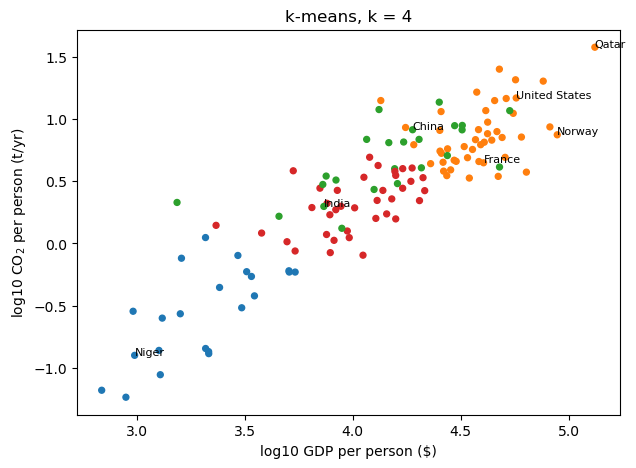

In [5]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X)
c["km"] = km.labels_

fig, ax = plt.subplots(figsize=(7, 5))
scatter(ax, c["km"], "k-means, k = 4")
plt.show()

Always translate the centers back into units you can read. `inverse_transform` undoes the
standardization, and undoing the log gives the geometric mean of each cluster.

In [6]:
centers = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=feat.columns)
readable = pd.DataFrame({
    "n":            c["km"].value_counts().sort_index(),
    "co2_pc (t)":   10 ** centers["log_co2_pc"],
    "gdp_pc ($)":   10 ** centers["log_gdp_pc"],
    "energy_pc (kWh)": 10 ** centers["log_energy_pc"],
    "coal_share":   centers["coal_share"],
}).round(2)
print(readable)
print()
for k in range(4):
    members = c[c["km"] == k].sort_values("population", ascending=False).index[:6]
    print(f"cluster {k}: {', '.join(members)}")

    n  co2_pc (t)  gdp_pc ($)  energy_pc (kWh)  coal_share
0  22        0.28     2053.71          1172.89        0.18
1  46        7.47    38633.10         48131.95        0.14
2  24        4.76    14736.12         18546.23        0.60
3  37        2.06    10344.56         10539.80        0.10

cluster 0: Nigeria, Bangladesh, Ethiopia, Democratic Republic of Congo, Tanzania, Kenya
cluster 1: United States, Russia, Japan, Iran, Germany, United Kingdom
cluster 2: India, China, Indonesia, Philippines, Vietnam, Turkey
cluster 3: Pakistan, Brazil, Mexico, Egypt, Thailand, Colombia


The algorithm was told nothing about geography or development, and it produced a low-income
group, a middle group, a rich group, and a coal-heavy group cutting across income. That is a
real structure in the data. It is also a structure the choice of features built in: with
`coal_share` removed there would be no coal cluster, because nothing would tell the algorithm
about fuel mix.

## 3. How many clusters?

$k$ is an input, not an output. Two standard diagnostics, neither of which is decisive.

**Inertia** is the total squared distance from each point to its center. It always falls as
$k$ grows, so you look for the "elbow" where it stops falling quickly. **Silhouette** compares
each point's distance to its own cluster with its distance to the nearest other cluster. Values
near 1 mean tight, separated clusters, and values near 0 mean the clusters overlap.

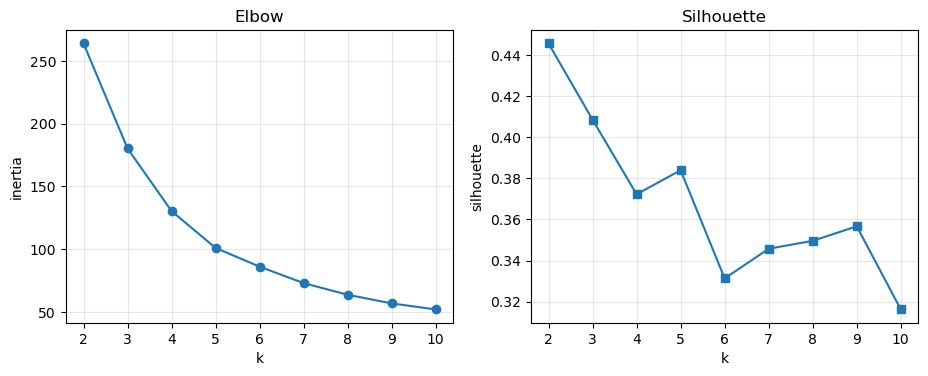

k= 2  inertia= 263.9  silhouette=0.446
k= 3  inertia= 180.2  silhouette=0.409
k= 4  inertia= 130.3  silhouette=0.372
k= 5  inertia= 100.9  silhouette=0.384
k= 6  inertia=  86.0  silhouette=0.331
k= 7  inertia=  72.9  silhouette=0.346
k= 8  inertia=  63.6  silhouette=0.350
k= 9  inertia=  56.7  silhouette=0.357
k=10  inertia=  51.9  silhouette=0.316


In [7]:
from sklearn.metrics import silhouette_score

ks = range(2, 11)
inertia = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
sil = [silhouette_score(X, KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)) for k in ks]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(list(ks), inertia, "o-"); axes[0].set_xlabel("k"); axes[0].set_ylabel("inertia"); axes[0].set_title("Elbow")
axes[1].plot(list(ks), sil, "s-"); axes[1].set_xlabel("k"); axes[1].set_ylabel("silhouette"); axes[1].set_title("Silhouette")
for ax in axes: ax.grid(alpha=0.3)
plt.show()
for k, i, s in zip(ks, inertia, sil):
    print(f"k={k:2d}  inertia={i:6.1f}  silhouette={s:.3f}")

No sharp elbow, and silhouette values that are modest everywhere. That is the normal outcome
on real data: countries lie along a continuum, not in separate clumps, and any $k$ is a
choice about how finely to slice it. The diagnostics rule out silly values. They do not hand
you the right one. State the choice and the reason for it.

## 4. K-means is not unique

The lecture makes this point and it is worth seeing. K-means starts from random centers and
finds a local optimum. Run it from a single random start several times and compare the
labelings with the **adjusted Rand index**, which is 1 when two partitions agree exactly
and near 0 when they agree no better than chance.

In [8]:
from sklearn.metrics import adjusted_rand_score

runs = [KMeans(n_clusters=4, n_init=1, random_state=seed).fit(X) for seed in range(6)]
print("inertia of each single-start run:", np.round([r.inertia_ for r in runs], 1))
print()
print("adjusted Rand index between run 0 and the others:")
for seed, r in enumerate(runs[1:], 1):
    print(f"  run {seed}: {adjusted_rand_score(runs[0].labels_, r.labels_):.2f}")

inertia of each single-start run: [134.6 148.  131.8 131.2 131.8 131.8]

adjusted Rand index between run 0 and the others:
  run 1: 0.50
  run 2: 0.46
  run 3: 0.63
  run 4: 0.46
  run 5: 0.63


Some runs land in the same place and some do not. This is why scikit-learn's default is
`n_init=10`, ten starts keeping the best. If a result changes when you change the seed, it is
not a finding.

## 5. DBSCAN: density, not centers

DBSCAN has no $k$. A point with at least `min_samples` neighbors within a radius `eps` is a
core point, cores that reach each other form a cluster, and anything not reachable from a core
is labeled $-1$: noise. Two things k-means cannot do follow from that: clusters of any
shape, and an explicit list of outliers.

The radius is a distance, so DBSCAN works best when distance means something physical. For this
section we leave the countries and use points on a map: the methane super-emitters that
[Carbon Mapper](https://carbonmapper.org) detected in the United States between January 2025
and September 2026, from the Tanager-1 satellite, NASA's EMIT instrument on the International
Space Station, and aircraft. Each row is one emitting site: its latitude and longitude, its
sector (oil and gas, landfill, coal mining, livestock, and a few others), and Carbon Mapper's
estimate of its emission rate in kilograms of methane per hour. Carbon Mapper builds this table
with DBSCAN itself, merging plumes seen within 250 meters of each other (1 kilometer for
landfills) into one site.

In [9]:
ch4 = pd.read_csv("/data9/CLMT5120/data/shr/methane_sources_us_2025_2026.csv")
print(len(ch4), "methane sources")
ch4["sector"].value_counts()

2027 methane sources


sector
oil and gas          1471
landfill              250
coal mining           176
livestock              93
other                  27
energy industries       6
wastewater              4
Name: count, dtype: int64

Distances on a sphere need the `haversine` metric, which gives the great-circle distance between
two points. scikit-learn's version takes latitude and longitude in radians, in that order, and
returns the distance in radians, so a radius in kilometers is divided by Earth's radius, 6,371
km. Start with a 50 km radius and at least 20 sites within it.

In [10]:
from sklearn.cluster import DBSCAN

coords = np.radians(ch4[["lat", "lon"]])
db = DBSCAN(eps=50 / 6371, min_samples=20, metric="haversine").fit(coords)
ch4["db"] = db.labels_
print("clusters:", ch4["db"].max() + 1, "| noise points:", (ch4["db"] == -1).sum())

table = pd.crosstab(ch4["db"], ch4["sector"])
table[["lat", "lon"]] = ch4.groupby("db")[["lat", "lon"]].mean().round(1)
table

clusters: 12 | noise points: 383


sector,coal mining,energy industries,landfill,livestock,oil and gas,other,wastewater,lat,lon
db,,,,,,,,,
-1,12,6,229,12,96,25,3,37.0,-96.7
0,0,0,0,0,149,0,0,28.1,-99.5
1,0,0,0,2,837,0,0,31.9,-103.0
2,0,0,1,0,31,0,0,32.1,-93.5
3,21,0,3,0,0,0,0,33.4,-87.2
4,0,0,4,0,47,0,0,35.2,-97.9
5,0,0,5,79,93,1,1,35.7,-119.4
6,0,0,0,0,62,0,0,36.8,-107.6
7,24,0,0,0,7,1,0,37.2,-81.9


Each row of the table is one cluster: how many sites of each sector it holds, and its mean
location. Row $-1$ is the noise. Now put the clusters on a map, and next to them the result of
k-means with the same number of clusters, run on the same coordinates.

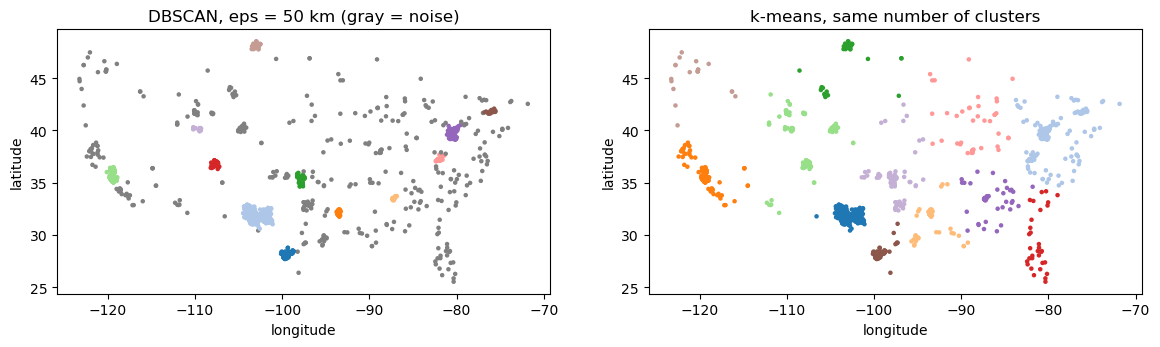

In [11]:
km_map = KMeans(n_clusters=ch4["db"].max() + 1, n_init=10, random_state=0).fit(ch4[["lon", "lat"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, labels, title in [(axes[0], ch4["db"], "DBSCAN, eps = 50 km (gray = noise)"),
                          (axes[1], km_map.labels_, "k-means, same number of clusters")]:
    ax.scatter(ch4["lon"], ch4["lat"], c=labels, s=5, vmin=0, vmax=19,
               cmap=plt.cm.tab20.with_extremes(under="gray"))
    ax.set(title=title, xlabel="longitude", ylabel="latitude", aspect=1.2)
plt.show()

Every DBSCAN cluster is a recognizable oil, gas, or coal region. Reading the table by mean
location: the Permian Basin in West Texas and New Mexico (839 sites, almost all oil and gas),
the Eagle Ford in South Texas, the Haynesville on the Texas-Louisiana border, the Anadarko Basin
in Oklahoma, the San Juan Basin at the Four Corners, the Uinta Basin in Utah, and the Bakken in
North Dakota. In California's San Joaquin Valley the cluster mixes oil fields with dairies.
Appalachia has three clusters: coal mines and gas wells around southwestern Pennsylvania and
northern West Virginia, coal mines along the Virginia-West Virginia border, and gas wells in
northeastern Pennsylvania. The twelfth is the coal mines of the Black Warrior Basin in Alabama.

The noise points are informative too. They include 229 of the 250 landfills. Landfills sit near
cities, a few per metropolitan area, so they are spread across the country and never reach the
density of an oil field. A site is noise when fewer than 20 sites lie within 50 km of it and
none of those is a core point. That says nothing about how much the site emits.

K-means finds the big basins too, because they are dense enough to pull a center toward them,
but it has to put every site in some cluster. It merges the three Appalachian clusters into one
and the San Juan and Uinta basins into another, and it spends three of its twelve clusters on
the Southeast, the Midwest, and the Pacific Northwest, where DBSCAN finds no dense group and
most sites are landfills.

One caution about what the clusters mean. A dense cluster is many detected sites, and that
depends on how often an area was observed as well as on how much methane leaks there. The map
shows where Carbon Mapper found emitters, not where every emitter is.

`eps` still matters. The sweep below reruns DBSCAN with radii from 10 to 400 km.

In [12]:
for radius in [10, 25, 50, 100, 200, 400]:
    lab = DBSCAN(eps=radius / 6371, min_samples=20, metric="haversine").fit_predict(coords)
    print(f"eps = {radius:3d} km: {lab.max() + 1:2d} clusters, {(lab == -1).sum():4d} noise points")

eps =  10 km: 11 clusters, 1360 noise points
eps =  25 km: 12 clusters,  563 noise points
eps =  50 km: 12 clusters,  383 noise points
eps = 100 km: 13 clusters,  331 noise points
eps = 200 km: 10 clusters,  181 noise points


eps = 400 km:  3 clusters,   19 noise points


From 25 to 100 km the number of clusters hardly changes, because the gaps between basins are
hundreds of kilometers wide. The picture falls apart only at the extremes: at 10 km two thirds
of the sites are noise, and at 400 km most of the sites join one cluster. Try 25 km in the
DBSCAN cell above and the Permian splits in two, roughly the Delaware Basin to the west and the
Midland Basin to the east. A result that holds across a wide range of `eps` is more trustworthy
than one that holds at a single value.

In an environmental dataset the same mechanism flags a broken sensor or an unusual event,
which is where Assignment 11 picks the idea up.

## 6. Gaussian mixture models: soft membership

Back to the countries. K-means gives every country exactly one label. A Gaussian mixture
model instead fits $k$ overlapping bell-shaped distributions and gives each country a
**probability** of belonging to each. That is the right answer for a continuum: a country halfway between two groups should
be reported as halfway, not forced to one side.

In [13]:
from sklearn.mixture import GaussianMixture

gm = GaussianMixture(n_components=4, n_init=5, random_state=0).fit(X)
c["gm"] = gm.predict(X)
resp = gm.predict_proba(X)
c["gm_confidence"] = resp.max(axis=1)

print("countries whose best component has probability below 0.6:")
amb = c[c["gm_confidence"] < 0.6].sort_values("gm_confidence")
print(amb[["gm", "gm_confidence"]].round(2).head(12))

countries whose best component has probability below 0.6:
                    gm  gm_confidence
country                              
Brazil               1           0.46
Spain                0           0.52
Cambodia             2           0.52
Slovakia             1           0.53
Croatia              0           0.55
Finland              3           0.57
Dominican Republic   3           0.57


Those are the countries a hard clustering silently mis-describes. Because a mixture model is a
probability model, it also gives a principled way to compare values of $k$: the **Bayesian
information criterion** penalizes the fit by the number of parameters, and lower is better.

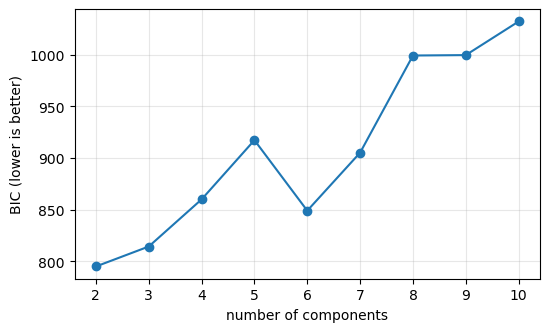

BIC prefers k = 2


In [14]:
bics = [GaussianMixture(n_components=k, n_init=5, random_state=0).fit(X).bic(X) for k in ks]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(list(ks), bics, "o-")
ax.set_xlabel("number of components")
ax.set_ylabel("BIC (lower is better)")
ax.grid(alpha=0.3)
plt.show()
print("BIC prefers k =", list(ks)[int(np.argmin(bics))])

## 7. Where k-means and the mixture model agree

Put the k-means and mixture model labelings of the countries side by side. Agreement between
methods that make different assumptions is weak evidence that a group is real. A group that
only one method finds is probably an artifact of that method's assumptions.

In [15]:
print(f"ARI, k-means vs GMM: {adjusted_rand_score(c['km'], c['gm']):.2f}")
print()
print(pd.crosstab(c["km"], c["gm"], rownames=["k-means"], colnames=["GMM"]))

ARI, k-means vs GMM: 0.31

GMM       0   1   2   3
k-means                
0         1   0  14   7
1        17  24   0   5
2         0   0   0  24
3        24   3   1   9


## Where this goes next

Three lessons to carry into Assignment 8, where the objects are grid cells described by twelve
months of temperature and twelve of precipitation rather than countries described by four
numbers. First, the features and their scaling decide what "similar" means, before any
algorithm runs. Second, $k$ is a choice you have to defend, not a number the data hands you.
Third, a clustering is a description, not a discovery: check it against something the
algorithm never saw, which for climate zones is the map, for the methane clusters is the sector
of each site, and for the countries is what you already know about them.